In [1]:
from pprint import pprint
import os, sys
from pathlib import Path
from typing import Optional, Any, Callable, Union
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor, as_completed
from copy import deepcopy
from collections import defaultdict
from time import perf_counter

# import wandb
# from dask.distributed import Client, as_completed
import networkx as nx
import torch
import numpy as np
import numpy.linalg as npla
import pandas as pd
from sklearn.metrics import (f1_score, precision_score, recall_score, 
                             roc_auc_score, precision_recall_curve, auc,
                             roc_curve)
from sklearn.model_selection import KFold
from tqdm import tqdm
import optuna
import omegaconf as oc
from omegaconf import OmegaConf
import matplotlib.pyplot as plt

from t_regs.solvers.manifold.minimax_problem import MinimaxProblem
from t_regs.solvers.manifold.rada import RADA_RGD
from t_regs.models.regression.tucker_nn_regressor import TuckerRegressor
from t_regs.models.regression.tucker_nn_bcd_v2 import TuckerRegressorBCD
from t_regs.synthetic_data.generate_lr_data import (
    generate_sparse_low_tucker_rank_tensor,
    generate_low_rank_data,
    generate_smooth_low_tucker_rank_tensor
    )
from t_regs.synthetic_data.regression import (
    generate_tensor_regression_predictors,
    generate_tensor_regression_response
    )

path = Path().cwd().parent.parent.parent
sys.path.append(str(path))

from experiments.synthetic.hp_study_utils import get_model, get_data
from experiments.synthetic.synthetic_study_utils import (
    register_resolvers,
    init_rada_rgd
    )

register_resolvers()

In [2]:
conf = OmegaConf.load('./../configs/study_0_a.yaml')

# pprint(OmegaConf.to_yaml(conf))
model_cfg = conf.model_cfg.copy()
pprint(model_cfg)

{'model_name': 'LR-Tucker', 'regressor': {'regression_type': 'logistic', 'feature_dims': '${data.dims}', 'feature_ranks': ['???', '???', '???'], 'feature_manifolds': ['${Steifel:${..feature_dims[0]}, ${..feature_ranks[0]}, ${...device}}', '${Steifel:${..feature_dims[1]}, ${..feature_ranks[1]}, ${...device}}', '${Steifel:${..feature_dims[2]}, ${..feature_ranks[2]}, ${...device}}']}, 'tau': 0.0, 'ldas': [0.0, 0.0, 0.0], 'lda_core': 0.0, 'thetas': [0.0, 0.0, 0.0], 'Ds': None, 'Ls': [None, None, None], 'subproblem_solvers': {'U_1': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[0]},${mul:${data.dims[0]},${..regressor.feature_ranks[0]}}}', 'U_2': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[1]},${mul:${data.dims[1]},${..regressor.feature_ranks[1]}}}', 'U_3': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[2]},${mul:${data.dims[2]},${..regressor.feature_ranks[2]}}}', 'C': '${init_rada_rgd:${rada_rgd_cfg},${..lda_core},${mul_list:${..regressor.feature_ranks}}}'}, 'dataloader_cfg': None, 'main_algorithm': '

In [3]:
conf.data.data_type = 'sparse_low_tucker_rank'
conf.data.cardinalities = [4, 4, 4]
conf.data.n_train = 1200
conf.data.seed = 1
pprint(conf.data)

{'regression_type': 'logistic', 'tensor_type': 'low_tucker_rank', 'dims': [30, 30, 30], 'ranks': [3, 3, 3], 'n_train': 1200, 'seed': 1, 'dtype': 'double', 'factor_graphs': [None, None, None], 'data_type': 'sparse_low_tucker_rank', 'cardinalities': [4, 4, 4]}


In [4]:
conf.model_cfg.regressor.feature_ranks[0] = 3
conf.model_cfg.regressor.feature_ranks[1] = 3
conf.model_cfg.regressor.feature_ranks[2] = 3
conf.model_cfg.verbosity = 2
conf.model_cfg.max_it= 100
conf.model_cfg.max_time= 100
conf.rada_rgd_cfg.Tk = 20
pprint(conf.model_cfg)

{'model_name': 'LR-Tucker', 'regressor': {'regression_type': 'logistic', 'feature_dims': '${data.dims}', 'feature_ranks': [3, 3, 3], 'feature_manifolds': ['${Steifel:${..feature_dims[0]}, ${..feature_ranks[0]}, ${...device}}', '${Steifel:${..feature_dims[1]}, ${..feature_ranks[1]}, ${...device}}', '${Steifel:${..feature_dims[2]}, ${..feature_ranks[2]}, ${...device}}']}, 'tau': 0.0, 'ldas': [0.0, 0.0, 0.0], 'lda_core': 0.0, 'thetas': [0.0, 0.0, 0.0], 'Ds': None, 'Ls': [None, None, None], 'subproblem_solvers': {'U_1': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[0]},${mul:${data.dims[0]},${..regressor.feature_ranks[0]}}}', 'U_2': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[1]},${mul:${data.dims[1]},${..regressor.feature_ranks[1]}}}', 'U_3': '${init_rada_rgd:${rada_rgd_cfg},${..ldas[2]},${mul:${data.dims[2]},${..regressor.feature_ranks[2]}}}', 'C': '${init_rada_rgd:${rada_rgd_cfg},${..lda_core},${mul_list:${..regressor.feature_ranks}}}'}, 'dataloader_cfg': None, 'main_algorithm': 'BCD_RADA_RGD

In [5]:
# torch.manual_seed(1)
data = get_data(conf.data)
model = get_model(conf.model_cfg, 'cuda:2')
data['X'] = data['X'].to(model.device)
data['y'] = data['y'].to(model.device)
X_train, X_val = data['X'][300:], data['X'][:300]
y_train, y_val = data['y'][300:].reshape(-1, 1), data['y'][:300].reshape(-1, 1)
model.fit(X_train,
          y_train,
          X_val=X_val,
          y_val=y_val
          )


Initializing with the HoSVD of the gradient evaluated at 0
Starting BCD_RGD Solver for Tucker Regression
Hyper-parameters:
{'coefficient_dims': (1, 30, 30, 30),
 'feature_dims': (30, 30, 30),
 'feature_ranks': (3, 3, 3),
 'lda_core': 0.0,
 'ldas': [0.0, 0.0, 0.0],
 'ranks': (1, 3, 3, 3),
 'regression_type': 'logistic',
 'task_dims': (1,),
 'task_ranks': (1,),
 'tau': 0.0,
 'thetas': [0.0, 0.0, 0.0]}
Iteration    Train score    Val score    Cost                Gradient norm    U_1 grad norm    U_2 grad norm    U_3 grad norm    C grad norm    
---------    -----------    ---------    ----------------    -------------    -------------    -------------    -------------    -----------    
  1          0.8611         0.6700       3.5810466025e-01    6.2569e-02       6.2569e-02       3.8392e-02       2.9337e-10       1.5155e-02     
  2          0.9189         0.6667       2.1539273850e-01    5.8277e-02       5.8277e-02       4.0493e-02       4.8199e-08       1.0511e-03     
  3          0.94

In [6]:
from t_regs.multilinear_ops.tensor_products import multi_mode_product as mmp

In [7]:
C = model.tucker_regressor.core
Us = model.tucker_regressor.Us
modes = [m-1 for m in  model.tucker_regressor.in_prod_dims]
B = mmp(C, Us, modes, transpose=False)
B_gt = data['B_gt'].to(device=C.device)
print((B*B_gt).sum()/(torch.linalg.vector_norm(B_gt) * torch.linalg.vector_norm(B)))
print(torch.linalg.vector_norm(B - B_gt)/torch.linalg.vector_norm(B_gt))

tensor(0.6152, device='cuda:2', dtype=torch.float64)
tensor(31.7740, device='cuda:2', dtype=torch.float64)


In [22]:
model.tucker_regressor.order

4

In [8]:
lda_range = np.logspace(-10, 1, 60)
results = defaultdict(list)
model_cpy_path =  deepcopy(model)
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 1
rada_rgd_cfg.Tk= 100
rada_rgd_cfg.max_it= 1000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.01
rada_rgd_cfg.rho = 2.5 # 2.5
rada_rgd_cfg.eps = 1e-8
# rada_rgd_cfg.beta1 = 1e4 * 900*2
mode = 3
baseline = {
    't_score': model._t_score,
    'v_score': model._v_score,
    't_loss': model._t_loss,
    'v_loss': model._v_loss,
}

for i, lda in enumerate(lda_range):
    ts = perf_counter()
    print(f"Running iteration {i+1}/{len(lda_range)} with lda={lda:.3e}")
    model_cpy_path = deepcopy(model_cpy_path)
    model_cpy_zero = deepcopy(model)

    model_cpy_path.ldas[mode-1] = lda
    model_cpy_zero.ldas[mode-1] = lda
    rada_rgd_cfg.R = float(lda*(30*3)**0.5)
    rada_rgd_cfg.beta1 = 30*2# float(1/(30 * 3 * lda/10))# 1e4 * 900*2
    problem, covariate_transform = model_cpy_path._initialize_U_subproblem(
        use_dloader=False,
        mode=mode,
        X=X_train,
        y=y_train,
        X_val=X_val,
        y_val=y_val,
        save_score_to_self=True,
        )
    # rada_rgd_solver = init_rada_rgd(
    #     rada_rgd_cfg,
    #     float(model_cpy_path.ldas[0]),
    #     90)
    rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
    rada_result = rada_rgd_solver.solve(
        problem,
        x0=model_cpy_path.tucker_regressor.Us[mode-1].detach().clone(),
        y0=model_cpy_path.solver_results[f'U_{mode}'].point.y,
    )
    model_cpy_path.solver_results['']
    results['path_grad_norm'].append(rada_result.gradient_norm)
    results['path_time'].append(perf_counter() - ts)
    with torch.no_grad():
        results['path_l1_norm'].append( float(lda*rada_result.point.x.abs().sum()))
        results['path_l1_surr_err'].append(float((lda*rada_result.point.x.abs().sum() - (rada_result.point.x*rada_result.point.y).sum()).abs()))
        results['path_cardinality'].append(float((rada_result.point.x.abs() <= 1e-6).sum()))
    model_cpy_path.solver_results[f'U_{mode}'] = rada_result
    model_cpy_path.tucker_regressor.Us[mode-1].requires_grad = False
    model_cpy_path.tucker_regressor.Us[mode-1].copy_(
        rada_result.point.x.data
        )
    with torch.no_grad():
        C = model_cpy_path.tucker_regressor.core
        Us = model_cpy_path.tucker_regressor.Us
        modes = [m-1 for m in  model.tucker_regressor.in_prod_dims]
        B = mmp(C, Us, modes, transpose=False)
        B_gt = data['B_gt'].to(device=C.device)
        cos_similarity = (B*B_gt).sum()/(torch.linalg.vector_norm(B_gt) * torch.linalg.vector_norm(B))
        fro_dist = torch.linalg.vector_norm(B - B_gt)/torch.linalg.vector_norm(B_gt)
        results['path_B_cos_sim'].append(cos_similarity)
        results['path_B_fro_dist'].append(fro_dist)

    # ts = perf_counter()
    # problem, covariate_transform = model_cpy_zero._initialize_U_subproblem(
    #     use_dloader=False,
    #     mode=1,
    #     X=X_train,
    #     y=y_train,
    #     X_val=X_val,
    #     y_val=y_val,
    #     save_score_to_self=True,
    #     )
    # # rada_rgd_solver = init_rada_rgd(rada_rgd_cfg, float(model_cpy_zero.ldas[0]), 90)
    # rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
    # rada_result = rada_rgd_solver.solve(
    #     problem,
    #     x0=model_cpy_zero.tucker_regressor.Us[0].detach().clone(),
    #     # y0=model_cpy.solver_results['U_1'].point.y,
    # )
    # results['zero_time'].append(perf_counter() - ts)
    results['lda'].append(lda)
    with torch.no_grad():
        results['zero_l1_norm'].append( float(lda*rada_result.point.x.abs().sum()))
        results['zero_l1_surr_err'].append(float((lda*rada_result.point.x.abs().sum() - (rada_result.point.x*rada_result.point.y).sum()).abs()))
        results['zero_cardinality'].append(float((rada_result.point.x.abs() <= 1e-6).sum()))
    results['path_t_loss'].append(model_cpy_path._t_loss)
    results['zero_t_loss'].append(model_cpy_zero._t_loss)
    results['path_v_loss'].append(model_cpy_path._v_loss)
    results['zero_v_loss'].append(model_cpy_zero._v_loss)
    results['path_v_score'].append(model_cpy_path._v_score)
    results['zero_v_score'].append(model_cpy_zero._v_score)
    results['zero_grad_norm'].append(rada_result.gradient_norm)

Running iteration 1/60 with lda=1.000e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.398 seconds.

Running iteration 2/60 with lda=1.536e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.347 seconds.

Running iteration 3/60 with lda=2.360e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.319 seconds.

Running iteration 4/60 with lda=3.625e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.347 seconds.

Running iteration 5/60 with lda=5.569e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.322 seconds.

Running iteration 6/60 with lda=8.555e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.320 seconds.

Running iteration 7/60 with lda=1.314e-09
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.319 seconds.

Running iteration 8/60 with lda=2.019e-09
RADA R

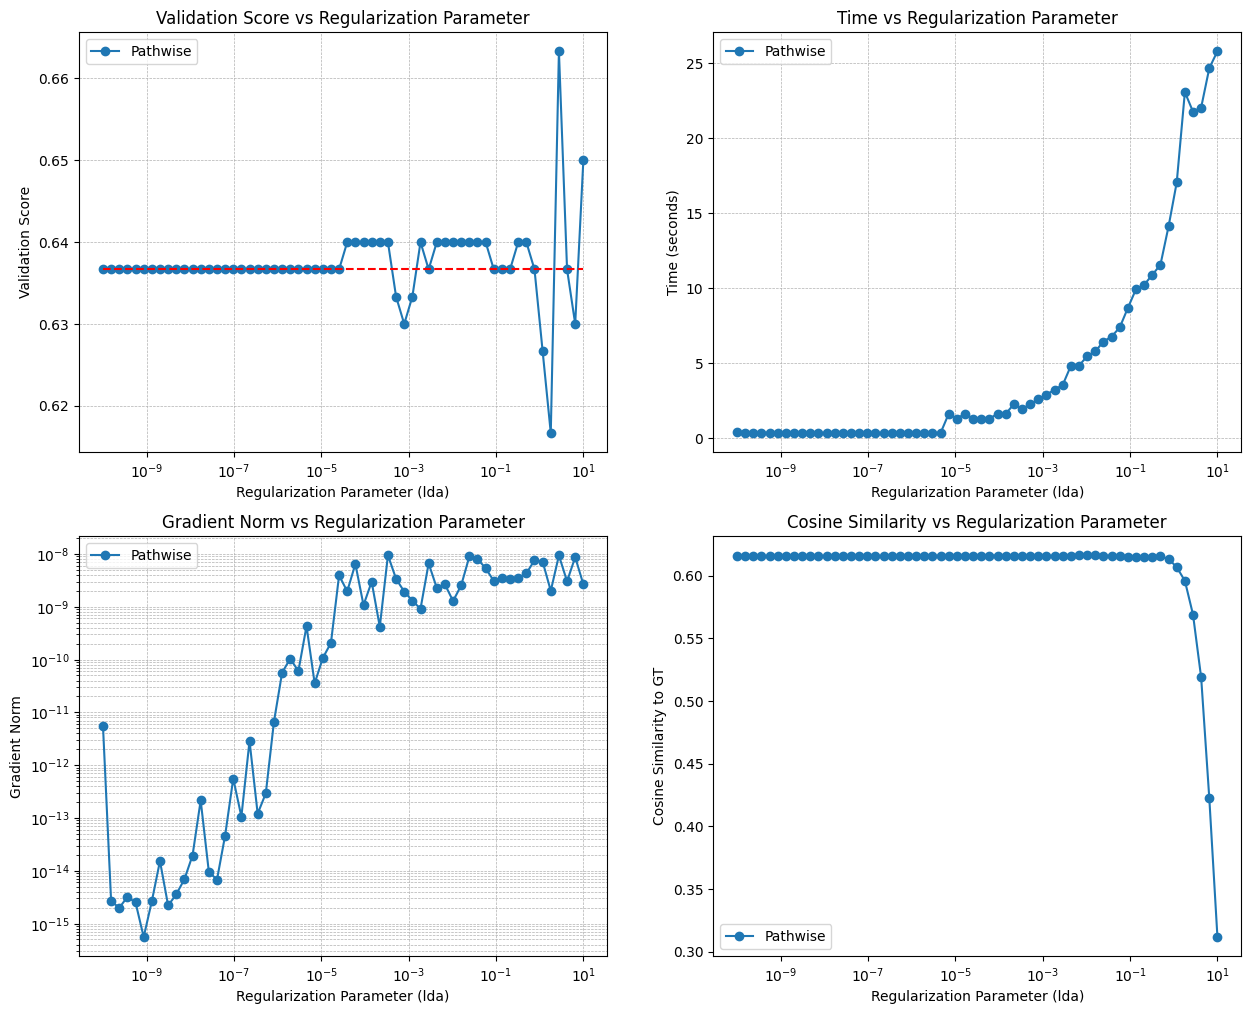

: 

In [ ]:
results['path_grad_norm'] = [float(x) for x in results['path_grad_norm']]
results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
# results['path_v_loss'] = [float(x) for x in results['path_v_loss']]
results['path_B_cos_sim'] = [float(x) for x in results['path_B_cos_sim']]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()
axes[0].plot(results['lda'], results['path_v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(baseline['v_score'], xmin=lda_range[0], xmax=lda_range[-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['path_time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[2].loglog(lda_range, results['path_grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (lda)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

axes[3].plot(results['lda'], results['path_B_cos_sim'], label='Pathwise', marker='o')
axes[3].set_xscale('log')
axes[3].set_xlabel('Regularization Parameter (lda)')
axes[3].set_ylabel('Cosine Similarity to GT')
axes[3].set_title('Cosine Similarity vs Regularization Parameter')
axes[3].legend()

In [ ]:
lda_range = np.logspace(-10, 1, 60)
results = defaultdict(list)
model_cpy_path =  deepcopy(model)
rada_rgd_cfg = conf.rada_rgd_cfg.copy()
rada_rgd_cfg.verbosity = 1
rada_rgd_cfg.Tk= 100
rada_rgd_cfg.max_it= 1000 #rada_rgd_cfg.max_it * 20
rada_rgd_cfg.c1 = 0.01
rada_rgd_cfg.rho = 1.5 # 2.5
rada_rgd_cfg.eps = 1e-8
# rada_rgd_cfg.beta1 = 1e4 * 900*2
mode = 2
baseline = {
    't_score': model._t_score,
    'v_score': model._v_score,
    't_loss': model._t_loss,
    'v_loss': model._v_loss,
}

for i, lda in enumerate(lda_range):
    ts = perf_counter()
    print(f"Running iteration {i+1}/{len(lda_range)} with lda={lda:.3e}")
    model_cpy_path = deepcopy(model_cpy_path)
    model_cpy_zero = deepcopy(model)

    model_cpy_path.ldas[mode-1] = lda
    model_cpy_zero.ldas[mode-1] = lda
    rada_rgd_cfg.R = float(lda*(30*3)**0.5)
    rada_rgd_cfg.beta1 = 0.1*30*3**0.5# float(1/(30 * 3 * lda/10))# 1e4 * 900*2
    problem, covariate_transform = model_cpy_path._initialize_U_subproblem(
        use_dloader=False,
        mode=mode,
        X=X_train,
        y=y_train,
        X_val=X_val,
        y_val=y_val,
        save_score_to_self=True,
        )
    # rada_rgd_solver = init_rada_rgd(
    #     rada_rgd_cfg,
    #     float(model_cpy_path.ldas[0]),
    #     90)
    rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
    rada_result = rada_rgd_solver.solve(
        problem,
        x0=model_cpy_path.tucker_regressor.Us[mode-1].detach().clone(),
        y0=model_cpy_path.solver_results[f'U_{mode}'].point.y,
    )
    model_cpy_path.solver_results['']
    results['path_grad_norm'].append(rada_result.gradient_norm)
    results['path_time'].append(perf_counter() - ts)
    with torch.no_grad():
        results['path_l1_norm'].append( float(lda*rada_result.point.x.abs().sum()))
        results['path_l1_surr_err'].append(float((lda*rada_result.point.x.abs().sum() - (rada_result.point.x*rada_result.point.y).sum()).abs()))
        results['path_cardinality'].append(float((rada_result.point.x.abs() <= 1e-6).sum()))
    model_cpy_path.solver_results[f'U_{mode}'] = rada_result
    model_cpy_path.tucker_regressor.Us[mode-1].requires_grad = False
    model_cpy_path.tucker_regressor.Us[mode-1].copy_(
        rada_result.point.x.data
        )
    with torch.no_grad():
        C = model_cpy_path.tucker_regressor.core
        Us = model_cpy_path.tucker_regressor.Us
        modes = [m-1 for m in  model.tucker_regressor.in_prod_dims]
        B = mmp(C, Us, modes, transpose=False)
        B_gt = data['B_gt'].to(device=C.device)
        cos_similarity = (B*B_gt).sum()/(torch.linalg.vector_norm(B_gt) * torch.linalg.vector_norm(B))
        fro_dist = torch.linalg.vector_norm(B - B_gt)/torch.linalg.vector_norm(B_gt)
        results['path_B_cos_sim'].append(cos_similarity)
        results['path_B_fro_dist'].append(fro_dist)

    # ts = perf_counter()
    # problem, covariate_transform = model_cpy_zero._initialize_U_subproblem(
    #     use_dloader=False,
    #     mode=1,
    #     X=X_train,
    #     y=y_train,
    #     X_val=X_val,
    #     y_val=y_val,
    #     save_score_to_self=True,
    #     )
    # # rada_rgd_solver = init_rada_rgd(rada_rgd_cfg, float(model_cpy_zero.ldas[0]), 90)
    # rada_rgd_solver = RADA_RGD(**rada_rgd_cfg)
    # rada_result = rada_rgd_solver.solve(
    #     problem,
    #     x0=model_cpy_zero.tucker_regressor.Us[0].detach().clone(),
    #     # y0=model_cpy.solver_results['U_1'].point.y,
    # )
    # results['zero_time'].append(perf_counter() - ts)
    results['lda'].append(lda)
    with torch.no_grad():
        results['zero_l1_norm'].append( float(lda*rada_result.point.x.abs().sum()))
        results['zero_l1_surr_err'].append(float((lda*rada_result.point.x.abs().sum() - (rada_result.point.x*rada_result.point.y).sum()).abs()))
        results['zero_cardinality'].append(float((rada_result.point.x.abs() <= 1e-6).sum()))
    results['path_t_loss'].append(model_cpy_path._t_loss)
    results['zero_t_loss'].append(model_cpy_zero._t_loss)
    results['path_v_loss'].append(model_cpy_path._v_loss)
    results['zero_v_loss'].append(model_cpy_zero._v_loss)
    results['path_v_score'].append(model_cpy_path._v_score)
    results['zero_v_score'].append(model_cpy_zero._v_score)
    results['zero_grad_norm'].append(rada_result.gradient_norm)

Running iteration 1/60 with lda=1.000e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.471 seconds.

Running iteration 2/60 with lda=1.536e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.441 seconds.

Running iteration 3/60 with lda=2.360e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.439 seconds.

Running iteration 4/60 with lda=3.625e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.457 seconds.

Running iteration 5/60 with lda=5.569e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.491 seconds.

Running iteration 6/60 with lda=8.555e-10
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.423 seconds.

Running iteration 7/60 with lda=1.314e-09
RADA RGD Optimizing...
Terminated - eps-RGS point reached after 1 iterations, 0.177 seconds.

Running iteration 8/60 with lda=2.019e-09
RADA R

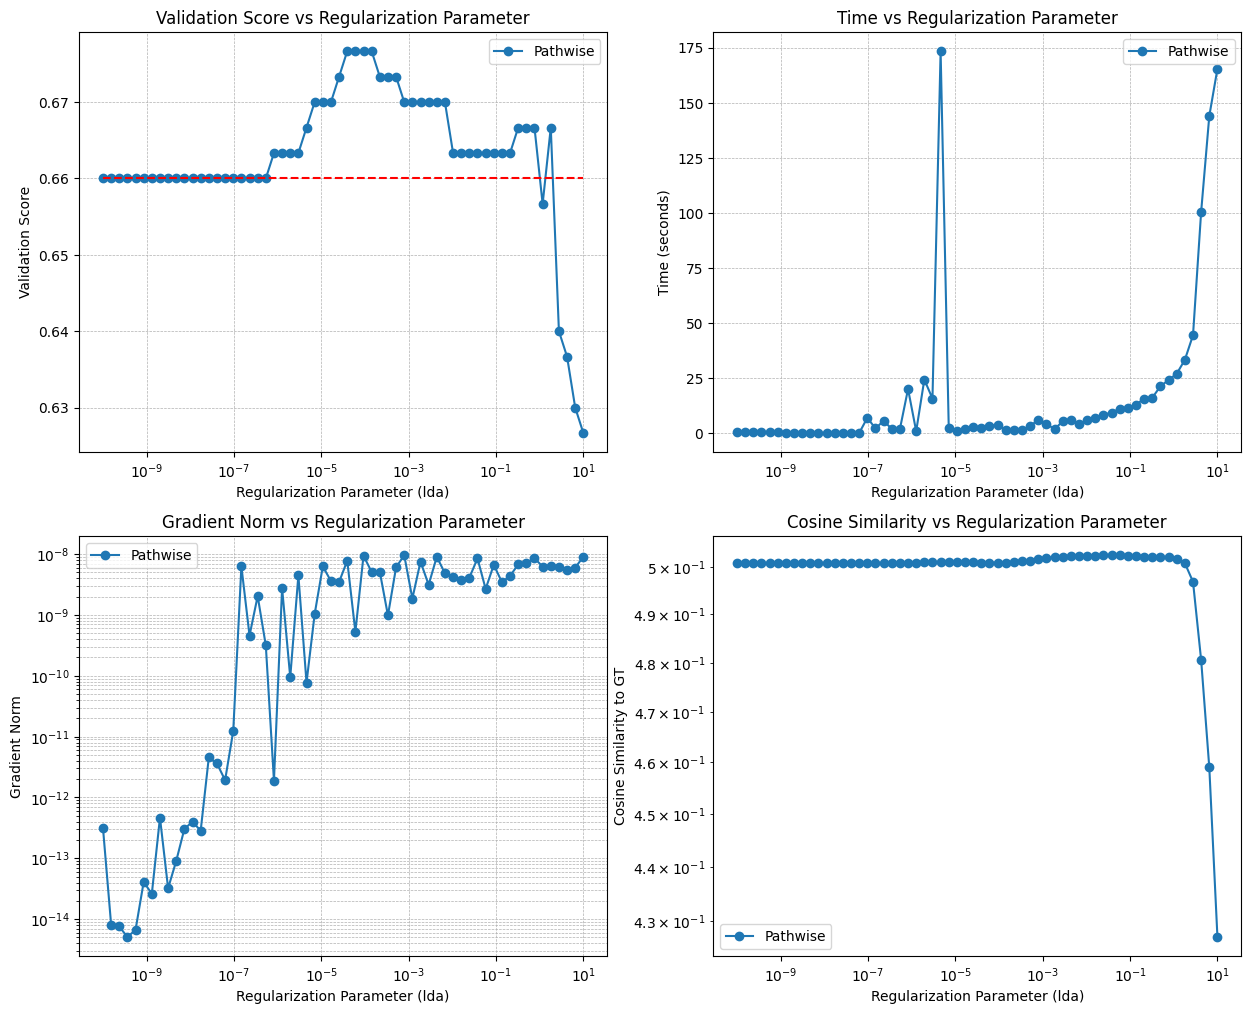

: 

In [ ]:
results['path_grad_norm'] = [float(x) for x in results['path_grad_norm']]
results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
results['path_v_loss'] = [float(x) for x in results['path_v_loss']]
results['path_B_cos_sim'] = [float(x) for x in results['path_B_cos_sim']]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()
axes[0].plot(results['lda'], results['path_v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['path_v_loss'], label='Val', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(baseline['v_score'], xmin=lda_range[0], xmax=lda_range[-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['path_time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[2].loglog(lda_range, results['path_grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (lda)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

# axes[3].plot(results['lda'], results['path_B_cos_sim'], label='Pathwise', marker='o')
axes[3].loglog(results['lda'], results['path_B_cos_sim'], label='Pathwise', marker='o')
axes[3].set_xscale('log')
# axes[3].set_yscale('log')
axes[3].set_xlabel('Regularization Parameter (lda)')
axes[3].set_ylabel('Cosine Similarity to GT')
axes[3].set_title('Cosine Similarity vs Regularization Parameter')
axes[3].legend()

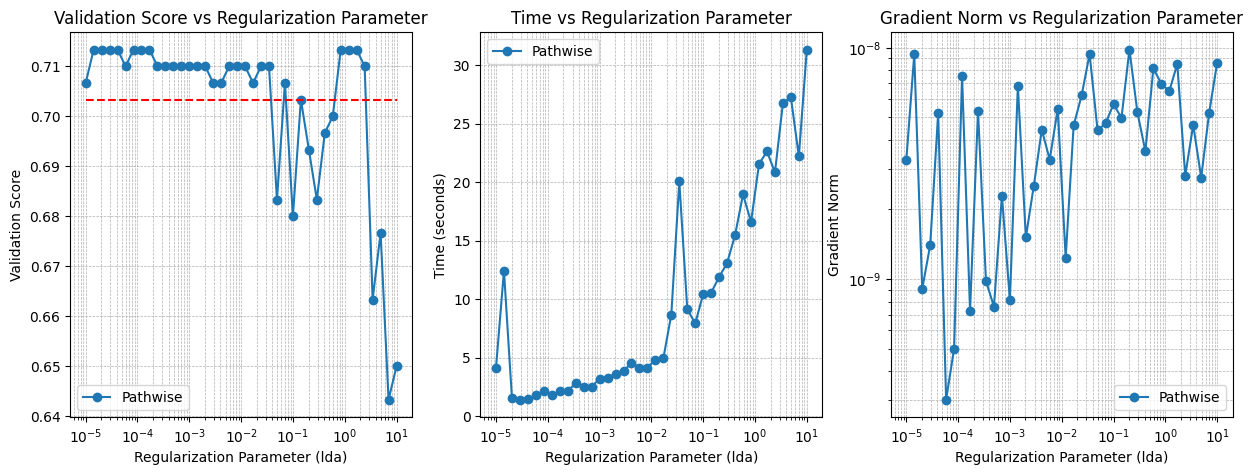

In [58]:
results['path_grad_norm'] = [float(x) for x in results['path_grad_norm']]
results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
# results['path_v_loss'] = [float(x) for x in results['path_v_loss']]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].plot(results['lda'], results['path_v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(baseline['v_score'], xmin=lda_range[0], xmax=lda_range[-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['path_time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[2].loglog(lda_range, results['path_grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (lda)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

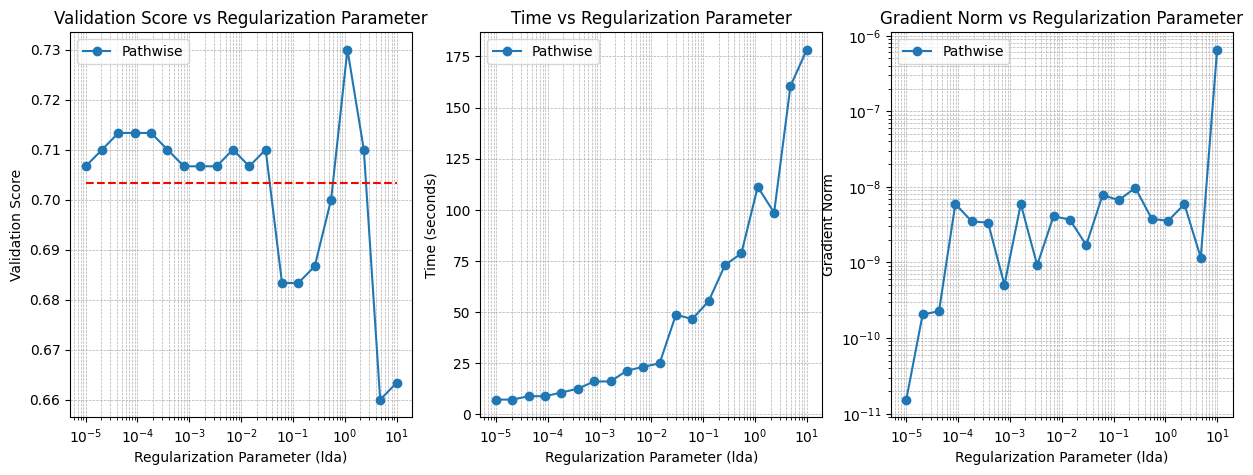

In [48]:
results['path_grad_norm'] = [float(x) for x in results['path_grad_norm']]
results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
# results['path_v_loss'] = [float(x) for x in results['path_v_loss']]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].plot(results['lda'], results['path_v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(baseline['v_score'], xmin=lda_range[0], xmax=lda_range[-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['path_time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[2].loglog(lda_range, results['path_grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (lda)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)

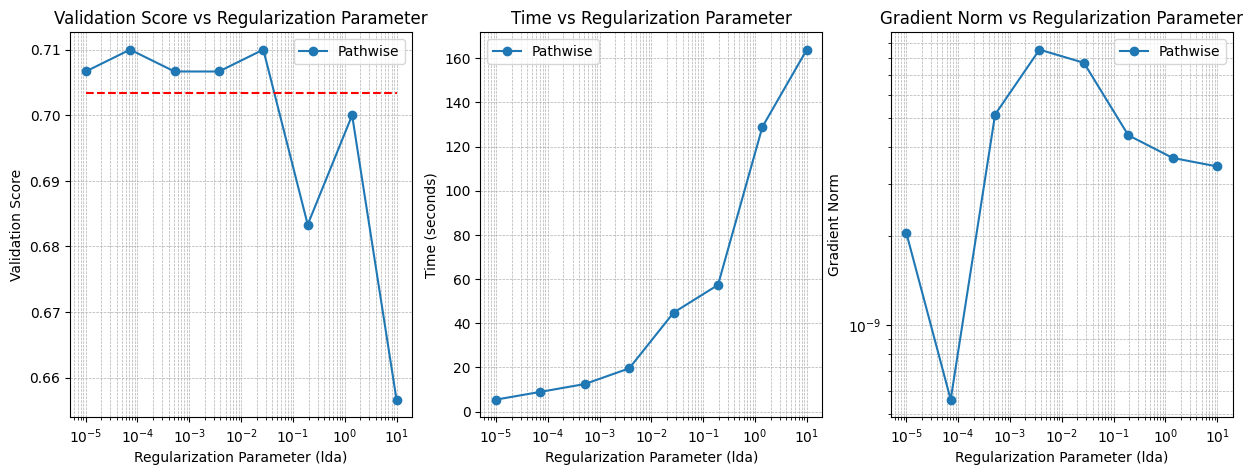

In [44]:
results['path_grad_norm'] = [float(x) for x in results['path_grad_norm']]
results['zero_grad_norm'] = [float(x) for x in results['zero_grad_norm']]
# results['zero_v_loss'] = [float(x) for x in results['zero_v_loss']]
# results['path_v_loss'] = [float(x) for x in results['path_v_loss']]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].plot(results['lda'], results['path_v_score'], label='Pathwise', marker='o')
# axes[0].plot(results['lda'], results['zero_v_score'], label='Zero Initialization', marker='x')
axes[0].set_xscale('log')
axes[0].set_xlabel('Regularization Parameter (lda)')
axes[0].set_ylabel('Validation Score')
axes[0].set_title('Validation Score vs Regularization Parameter')
axes[0].legend()
axes[0].hlines(baseline['v_score'], xmin=lda_range[0], xmax=lda_range[-1], 
               colors='r', linestyles='dashed', label='Baseline Validation Score')
# axes[0].hlines(float(baseline['v_loss']), xmin=lda_range[0], xmax=lda_range[-1], 
#                colors='r', linestyles='dashed', label='Baseline Validation Score')
axes[0].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[1].plot(results['lda'], results['path_time'], label='Pathwise', marker='o')
# axes[1].plot(results['lda'], results['zero_time'], label='Zero Initialization', marker='x')
axes[1].set_xscale('log')
axes[1].set_xlabel('Regularization Parameter (lda)')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Time vs Regularization Parameter')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', linewidth=0.5)
axes[2].loglog(lda_range, results['path_grad_norm'], label='Pathwise', marker='o')
# axes[2].loglog(lda_range, results['zero_grad_norm'], label='Zero Initialization', marker='x')
axes[2].set_xscale('log')
axes[2].set_xlabel('Regularization Parameter (lda)')
axes[2].set_ylabel('Gradient Norm')
axes[2].set_title('Gradient Norm vs Regularization Parameter')
axes[2].legend()
axes[2].grid(True, which='both', linestyle='--', linewidth=0.5)